# The CV Photonic Receiver: Where Continuous Fields Become Bits

**Colin Casey, 2026.** Library: `dgs/cv_receiver.py` (tests: `tests/test_cv_receiver.py`). Follows up on the claim in `hydrogen_n2_polar.ipynb` §7:

> *"A CV photonic processor needs exactly that kind of continuous-field readout. The discrete/continuous boundary is where the receiver design work sits."*

This notebook tests that claim with numbers, and **corrects part of it**.

## In plain words

A continuous-variable (CV) quantum processor stores information in the continuous **quadratures** $x,p$ of light pulses. To read them out, a **homodyne receiver** mixes the signal with a strong reference pulse, the local oscillator (LO), and subtracts two photocurrents. The difference is proportional to one quadrature. Four things decide whether the quantum information survives:

1. **Loss.** Every lost photon is replaced by vacuum noise, and squeezing (noise below vacuum) fades fast.
2. **Amplifiers.** The fiber amplifiers time-stretch uses are *phase-insensitive*. Physics forces them to add at least half a vacuum unit of noise, which erases squeezing. **So a classical time-stretch front end cannot carry CV quantum states.** Only *phase-sensitive* (parametric) amplifiers can amplify one quadrature without adding noise.
3. **Mode matching.** The homodyne only sees the part of the signal that shares the LO's pulse shape. Dispersion chirps the signal, and an unchirped LO then wastes most of the squeezing. **Here dispersion-assisted GS does belong in the receiver,** as a *classical calibration* step: measure the mode's chirp from intensity-only data and shape the LO to match.
4. **The discrete/continuous boundary.** A GKP qubit stores a bit as a comb of peaks spaced $\sqrt\pi$ in $x$, and the receiver decodes it by rounding. Squeezing, loss and ADC bits set the error rate.

| § | Question | Result type |
|---|---|---|
| 1 | Receiver chain | diagram |
| 2 | Fig. 1: how loss and amplifiers eat squeezing | closed forms |
| 3 | Fig. 2: how much a chirp costs | closed form + numeric overlap |
| 4 | Fig. 3: GS calibration of the LO (2 vs 3 planes, noise, denoising) | simulation |
| 5 | Fig. 4: GKP decoding vs squeezing, loss, ADC bits | exact sum + Monte Carlo |
| 6 | Receiver spec sheet; corrected claim | summary |

Conventions: $x=(a+a^\dagger)/\sqrt2$, vacuum variance $\tfrac12$, squeezing in dB relative to vacuum. Kernel: **py312**.

In [1]:
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import cv_receiver as cv
from dgs import gs_core
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. The receiver chain

```
 CV processor ─► signal mode (chirped by on-chip/fiber dispersion) ─┐
                                                                    ├─► 50:50 ─► PD+ ─┐
 pulse shaper ◄─ GS calibration (§4) ◄─ 3 intensity traces          │            PD- ─┴─► (−) ─► TIA ─► ADC ─► decode (§5)
      │            of a bright pulse in the same mode               │
      └─────────────────────────► shaped LO ────────────────────────┘
```
Efficiency budget: $\eta_\text{total}=\eta_\text{det}\times|\langle\text{LO}|\text{signal}\rangle|^2\times\eta_\text{optics}$. Everything below either preserves or spends this budget.

## 2. Figure 1: loss and amplifiers

**Loss:** $V\to\eta V+(1-\eta)\tfrac12$. **Phase-insensitive amplifier** (Caves limit): $V\to GV+(G-1)\tfrac12$, so referred to the input it adds $(1-1/G)\tfrac12\to\tfrac12$. **Ideal phase-sensitive amplifier:** $V_x\to GV_x$, $V_p\to V_p/G$, adding no noise.

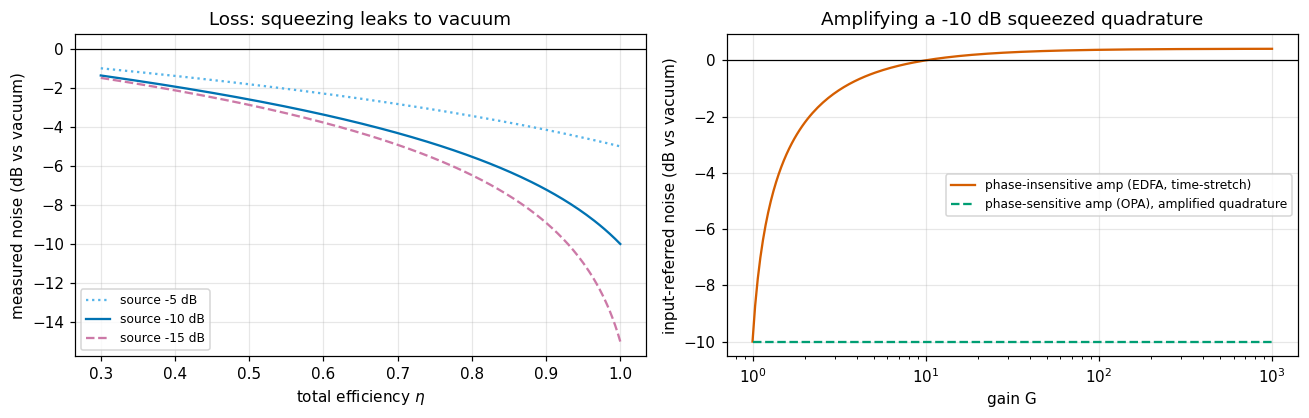

Figure 1. Left: measured noise of a squeezed quadrature against total efficiency for -5 dB (dotted sky blue), -10 dB (solid blue) and -15 dB (dashed purple) sources; the black line is vacuum. Even 90% efficiency turns -15 dB into about -8.9 dB. Right: input-referred noise of a -10 dB quadrature after amplification. The phase-insensitive amplifier (solid red) reaches vacuum level once G is large: the squeezing is erased. The phase-sensitive amplifier (dashed green) keeps -10 dB at any gain.


,eta,measured_from_-5dB,measured_from_-10dB,measured_from_-15dB
0,1.00,-5.00,-10.00,-15.00
1,0.95,-4.55,-8.39,-10.97
2,0.90,-4.15,-7.21,-8.91
3,0.80,-3.44,-5.53,-6.47
4,0.50,-1.82,-2.60,-2.88


In [2]:
eta = np.linspace(0.3, 1, 200)
G = np.logspace(0, 3, 200)
V10 = cv.variance_from_db(-10)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
for s_, c_, ls in [(-5, OI['sky'], ':'), (-10, OI['blue'], '-'), (-15, OI['purple'], '--')]:
    ax[0].plot(eta, cv.measured_squeezing_db(s_, eta), ls, color=c_, label=f'source {s_} dB')
ax[0].axhline(0, color=OI['black'], lw=0.8)
ax[0].set(xlabel='total efficiency $\\eta$', ylabel='measured noise (dB vs vacuum)', title='Loss: squeezing leaks to vacuum'); ax[0].legend(fontsize=8)
ax[1].semilogx(G, cv.db(cv.after_pia(V10, G)/G), '-', color=OI['red'], label='phase-insensitive amp (EDFA, time-stretch)')
ax[1].semilogx(G, cv.db(cv.after_psa(V10, cv.VACUUM**2/V10, G)[0]/G), '--', color=OI['green'], label='phase-sensitive amp (OPA), amplified quadrature')
ax[1].axhline(0, color=OI['black'], lw=0.8)
ax[1].set(xlabel='gain G', ylabel='input-referred noise (dB vs vacuum)', title='Amplifying a -10 dB squeezed quadrature'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 1. Left: measured noise of a squeezed quadrature against total efficiency for -5 dB (dotted sky blue), -10 dB (solid '
      'blue) and -15 dB (dashed purple) sources; the black line is vacuum. Even 90% efficiency turns -15 dB into about -8.9 dB. '
      'Right: input-referred noise of a -10 dB quadrature after amplification. The phase-insensitive amplifier (solid red) '
      'reaches vacuum level once G is large: the squeezing is erased. The phase-sensitive amplifier (dashed green) keeps -10 dB at any gain.')
rows = [dict(eta=e_, **{f'measured_from_{s_}dB': float(cv.measured_squeezing_db(s_, e_)) for s_ in (-5, -10, -15)}) for e_ in (1.0, 0.95, 0.9, 0.8, 0.5)]
pd.DataFrame(rows).round(2)

## 3. Figure 2: the cost of a chirp

Dispersion turns the signal's mode $e^{-t^2/2T_0^2}$ into $e^{-(1+iC)t^2/2T_0^2}$. An unchirped LO of the same width sees only

<IPython.core.display.Math object>

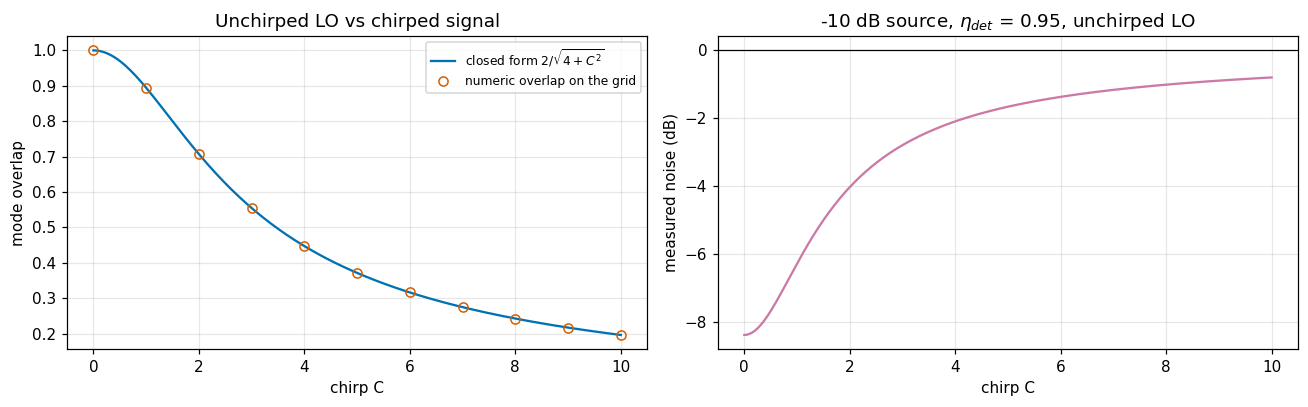

Figure 2. Left: overlap between an unchirped LO and a chirped signal mode against chirp C; the closed form (solid blue) passes through the numeric overlaps (open red circles). Right: what that does to a -10 dB squeezed source with a 95% detector (solid purple): at C = 4 the overlap is 0.447 and only -2.09 dB of squeezing is seen.


In [3]:
Cs, T0s = sp.symbols('C T_0', positive=True)
tt_ = sp.symbols('t', real=True)
ov_sym = sp.simplify(sp.Abs(sp.integrate(sp.exp(-(2 + sp.I*Cs)*tt_**2/(2*T0s**2)), (tt_, -sp.oo, sp.oo)))**2
                     / sp.integrate(sp.exp(-tt_**2/T0s**2), (tt_, -sp.oo, sp.oo))**2)
display(Math(r'|\langle \mathrm{LO}|\mathrm{sig}\rangle|^2 = ' + sp.latex(sp.simplify(ov_sym))))
n = 1024; t = np.arange(n) - n/2; T0 = 40.0
C = np.linspace(0, 10, 200)
Cn = np.arange(0, 11, 1.0)
ov_num = [cv.mode_overlap(cv.chirped_gaussian(t, T0, 0), cv.chirped_gaussian(t, T0, c_)) for c_ in Cn]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(C, cv.gaussian_chirp_overlap(C), '-', color=OI['blue'], label='closed form $2/\\sqrt{4+C^2}$')
ax[0].plot(Cn, ov_num, 'o', mfc='none', color=OI['red'], label='numeric overlap on the grid')
ax[0].set(xlabel='chirp C', ylabel='mode overlap', title='Unchirped LO vs chirped signal'); ax[0].legend(fontsize=8)
ax[1].plot(C, cv.measured_squeezing_db(-10, 0.95*cv.gaussian_chirp_overlap(C)), '-', color=OI['purple'])
ax[1].axhline(0, color=OI['black'], lw=0.8)
ax[1].set(xlabel='chirp C', ylabel='measured noise (dB)', title='-10 dB source, $\\eta_{det}$ = 0.95, unchirped LO')
plt.tight_layout(); plt.show()
print('Figure 2. Left: overlap between an unchirped LO and a chirped signal mode against chirp C; the closed form (solid blue) '
      'passes through the numeric overlaps (open red circles). Right: what that does to a -10 dB squeezed source with a 95% '
      f'detector (solid purple): at C = 4 the overlap is {cv.gaussian_chirp_overlap(4):.3f} and only '
      f'{cv.measured_squeezing_db(-10, 0.95*cv.gaussian_chirp_overlap(4)):.2f} dB of squeezing is seen.')

## 4. Figure 3: calibrating the LO with dispersion-assisted GS

Send a **bright classical pulse** through the same mode, record intensities at $D=0$ and at dispersions $D_1,D_2$ (the repo's $|D|\gtrsim5000$ regime), retrieve the complex mode, and program the LO pulse shaper to match. Three findings come out of the simulation:

* **Two planes are not enough.** $|E(t)|^2$ plus one dispersed trace can be fitted perfectly by a *wrong* chirp, because the dispersed width depends quadratically on $C$. Three planes break the tie.
* **Local minima.** Large chirps need a few quadratic-phase starting guesses (multistart).
* **Noise.** Noise in the dark tails corrupts the projections. Low-pass filtering plus a 3σ floor fixes most of it.

,planes,intensity_mismatch,overlap_with_true_mode
0,D=0 + one D,1.677348e-32,0.44912
1,D=0 + two D (multistart),1.120803e-32,1.00000


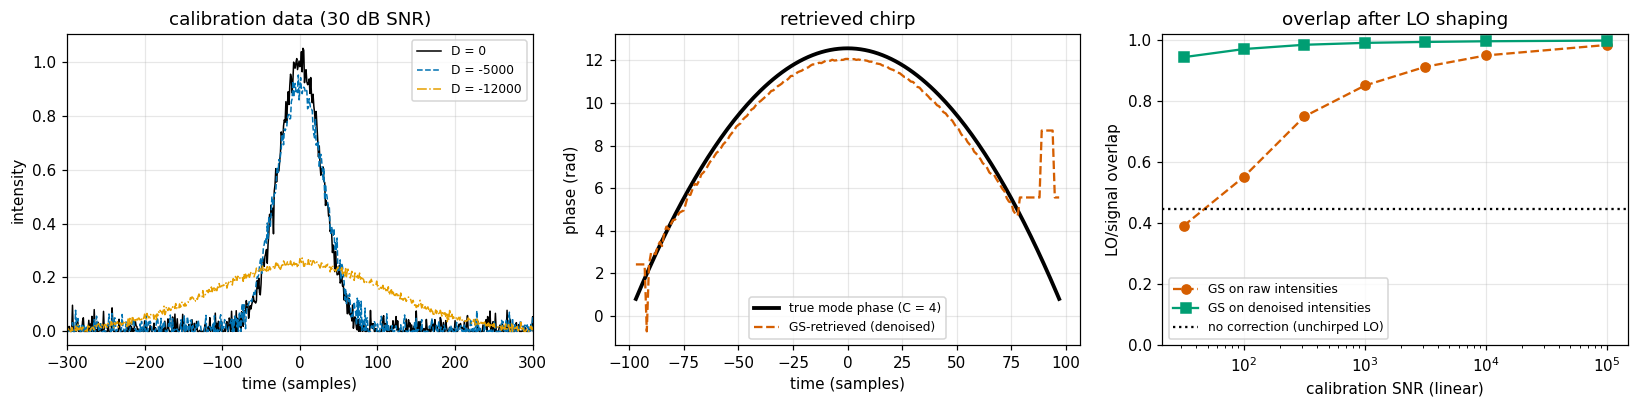

Figure 3. Left: the three calibration intensity traces at 30 dB SNR: D = 0 (solid black) and the two dispersed traces (dashed blue, dash-dot orange). Middle: the true quadratic phase of the chirped mode (thick black) and the phase retrieved by three-plane GS after denoising (dashed red, shifted by a constant): they agree across the pulse core; beyond |t| ~ 80 the denoiser zeroed the intensity, so the retrieved phase there is undefined and carries no weight. Right: LO/signal overlap after shaping the LO to the retrieved mode against calibration SNR, averaged over 3 noise seeds: raw intensities (red circles, dashed) vs denoised (green squares, solid); the dotted black line is the uncorrected overlap. Raw GS can be worse than doing nothing at low SNR.


,raw,denoised
snr_db,,
15,0.3920,0.9446
20,0.5530,0.9713
25,0.7505,0.9853
30,0.8518,0.9915
35,0.9132,0.9945
40,0.9503,0.9968
50,0.9846,0.9990


In [4]:
Cs_true = 4.0
E = cv.chirped_gaussian(t, T0, Cs_true)
Ds = [-5000.0, -12000.0]
I = cv.calibration_intensities(E, Ds)
g2, e2 = cv.gs_multiplane(I[0], I[1:2], Ds[:1], np.sqrt(I[0]).astype(complex), 500)
g3, e3, a3 = cv.retrieve_mode(I[0], I[1:], Ds, T0)
display(pd.DataFrame([dict(planes='D=0 + one D', intensity_mismatch=e2, overlap_with_true_mode=cv.mode_overlap(g2, E)),
                      dict(planes='D=0 + two D (multistart)', intensity_mismatch=e3, overlap_with_true_mode=cv.mode_overlap(g3, E))]))
snrs = [15, 20, 25, 30, 35, 40, 50]
rows = []
for snr in snrs:
    for seed in range(3):
        In = cv.calibration_intensities(E, Ds, snr_db=snr, seed=seed)
        raw = cv.mode_overlap(cv.retrieve_mode(In[0], In[1:], Ds, T0)[0], E)
        J = [cv.denoise_intensity(x_, 0.02, snr) for x_ in In]
        den = cv.mode_overlap(cv.retrieve_mode(J[0], J[1:], Ds, T0)[0], E)
        rows.append(dict(snr_db=snr, seed=seed, raw=raw, denoised=den))
cal = pd.DataFrame(rows).groupby('snr_db')[['raw', 'denoised']].mean()
In30 = cv.calibration_intensities(E, Ds, snr_db=30, seed=0)
J30 = [cv.denoise_intensity(x_, 0.02, 30) for x_ in In30]
g30 = cv.retrieve_mode(J30[0], J30[1:], Ds, T0)[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for x_, lab, c_, ls in zip(In30, ['D = 0', 'D = -5000', 'D = -12000'], [OI['black'], OI['blue'], OI['orange']], ['-', '--', '-.']):
    ax[0].plot(t, x_, ls, color=c_, lw=1, label=lab)
ax[0].set(xlim=(-300, 300), xlabel='time (samples)', ylabel='intensity', title='calibration data (30 dB SNR)'); ax[0].legend(fontsize=8)
m_ = np.abs(E) > 0.05
ph_true = np.unwrap(np.angle(E[m_])); ph_ret = np.unwrap(np.angle(g30[m_]))
ph_ret += np.mean(ph_true - ph_ret)
ax[1].plot(t[m_], ph_true, '-', color=OI['black'], lw=2.5, label='true mode phase (C = 4)')
ax[1].plot(t[m_], ph_ret, '--', color=OI['red'], label='GS-retrieved (denoised)')
ax[1].set(xlabel='time (samples)', ylabel='phase (rad)', title='retrieved chirp'); ax[1].legend(fontsize=8)
ax[2].semilogx(10**(cal.index/10), cal.raw, 'o--', color=OI['red'], label='GS on raw intensities')
ax[2].semilogx(10**(cal.index/10), cal.denoised, 's-', color=OI['green'], label='GS on denoised intensities')
ax[2].axhline(cv.gaussian_chirp_overlap(Cs_true), color=OI['black'], ls=':', label='no correction (unchirped LO)')
ax[2].set(xlabel='calibration SNR (linear)', ylabel='LO/signal overlap', ylim=(0, 1.02), title='overlap after LO shaping'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 3. Left: the three calibration intensity traces at 30 dB SNR: D = 0 (solid black) and the two dispersed traces (dashed '
      'blue, dash-dot orange). Middle: the true quadratic phase of the chirped mode (thick black) and the phase retrieved by '
      'three-plane GS after denoising (dashed red, shifted by a constant): they agree across the pulse core; beyond |t| ~ 80 '
      'the denoiser zeroed the intensity, so the retrieved phase there is undefined and carries no weight. Right: LO/signal overlap after shaping the LO to the retrieved '
      'mode against calibration SNR, averaged over 3 noise seeds: raw intensities (red circles, dashed) vs denoised (green '
      'squares, solid); the dotted black line is the uncorrected overlap. Raw GS can be worse than doing nothing at low SNR.')
cal.round(4)

In [5]:
eta_det = 0.95
rows = [dict(LO='unchirped (no calibration)', overlap=cv.gaussian_chirp_overlap(Cs_true)),
        dict(LO='GS-shaped, 30 dB calibration, denoised', overlap=cv.mode_overlap(g30, E)),
        dict(LO='perfect mode match', overlap=1.0)]
for r_ in rows:
    r_['eta_total'] = eta_det*r_['overlap']
    r_['measured_squeezing_dB_from_-10dB'] = float(cv.measured_squeezing_db(-10, r_['eta_total']))
print(f'-10 dB source, chirp C = {Cs_true}, detector efficiency {eta_det}:')
pd.DataFrame(rows).round(4)

-10 dB source, chirp C = 4.0, detector efficiency 0.95:


,LO,overlap,eta_total,measured_squeezing_dB_from_-10dB
0,unchirped (no calibration),0.4472,0.4249,-2.0927
1,"GS-shaped, 30 dB calibration, denoised",0.9920,0.9424,-8.1859
2,perfect mode match,1.0000,0.9500,-8.3863


## 5. Figure 4: the discrete/continuous boundary, GKP decoding

A GKP qubit puts logical 0 at $x\in2\sqrt\pi\,\mathbb Z$ and logical 1 at $x\in\sqrt\pi+2\sqrt\pi\,\mathbb Z$. The receiver outputs bit $=\operatorname{round}(x/\sqrt\pi)\bmod2$. Finite squeezing, loss (equivalent to Gaussian shifts with variance $(1-\eta)/2\eta$ after rescaling) and ADC quantization (variance $\text{LSB}^2/12$) add up to a total noise $\sigma$. The error probability is the Gaussian weight that lands in an odd-shifted cell. Leading term: $\operatorname{erfc}\!\big(\sqrt\pi/(2\sqrt2\,\sigma)\big)$.

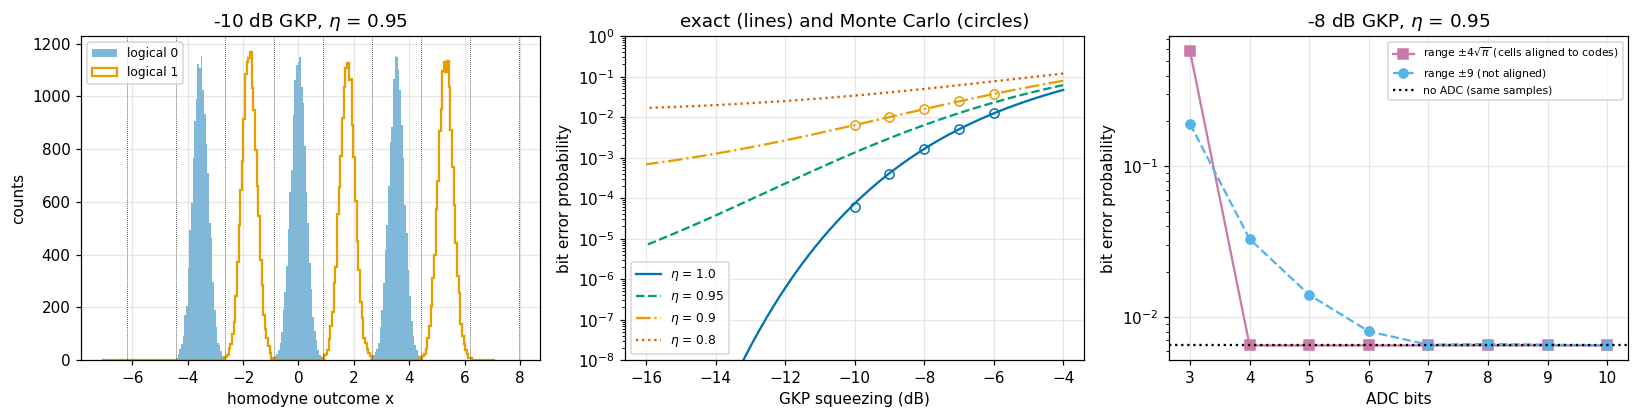

Figure 4. Left: homodyne histograms for GKP logical 0 (filled blue) and 1 (orange outline) at -10 dB squeezing and 95% efficiency; dotted lines are the decision boundaries at half-integer multiples of sqrt(pi). Middle: bit error probability against GKP squeezing for efficiencies 1, 0.95, 0.9, 0.8 (solid blue, dashed green, dash-dot orange, dotted red), exact cell sums, with Monte Carlo checks (open circles) for 1 and 0.9. Right: error against ADC resolution at -8 dB, 95%. With a +-4 sqrt(pi) range (purple squares) every decision boundary lands on an ADC code boundary, so from 4 bits the hard decision is identical to no ADC at all (dotted black, same noise samples). With a +-9 range (sky-blue circles; 9/sqrt(pi) = 5.08) the boundaries fall inside codes, and it takes 7 bits to come within 5% of it. Choosing the range is itself a design parameter.


,adc_bits,aligned_range,misaligned_range,ideal
0,3,0.583577,0.191452,0.006488
1,4,0.006488,0.032965,0.006488
2,5,0.006488,0.014070,0.006488
3,6,0.006488,0.008040,0.006488
4,7,0.006488,0.006560,0.006488
5,8,0.006488,0.006630,0.006488
6,9,0.006488,0.006562,0.006488
7,10,0.006488,0.006490,0.006488


In [6]:
rng = np.random.default_rng(3)
nh = 40000
sig = np.sqrt(cv.gkp_noise_variance(-10, eta=0.95))
x0 = cv.SQRT_PI*2*rng.integers(-1, 2, nh) + sig*rng.standard_normal(nh)
x1 = cv.SQRT_PI*(2*rng.integers(-1, 2, nh) + 1) + sig*rng.standard_normal(nh)
s_grid = np.linspace(-4, -16, 60)
s_mc = np.arange(-6, -11, -1.0)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
b_ = np.linspace(-4*cv.SQRT_PI, 4*cv.SQRT_PI, 240)
ax[0].hist(x0, bins=b_, histtype='stepfilled', alpha=0.5, color=OI['blue'], label='logical 0')
ax[0].hist(x1, bins=b_, histtype='step', lw=1.5, color=OI['orange'], label='logical 1')
for k in range(-4, 5):
    ax[0].axvline((k + 0.5)*cv.SQRT_PI, color=OI['black'], lw=0.5, ls=':')
ax[0].set(xlabel='homodyne outcome x', ylabel='counts', title='-10 dB GKP, $\\eta$ = 0.95'); ax[0].legend(fontsize=8)
for e_, c_, ls in [(1.0, OI['blue'], '-'), (0.95, OI['green'], '--'), (0.9, OI['orange'], '-.'), (0.8, OI['red'], ':')]:
    ax[1].semilogy(s_grid, [cv.gkp_error_exact(np.sqrt(cv.gkp_noise_variance(s_, eta=e_))) for s_ in s_grid], ls, color=c_, label=f'$\\eta$ = {e_}')
    if e_ in (1.0, 0.9):
        ax[1].semilogy(s_mc, [max(cv.gkp_monte_carlo(s_, eta=e_, n=400000), 1e-7) for s_ in s_mc], 'o', mfc='none', color=c_)
ax[1].set(xlabel='GKP squeezing (dB)', ylabel='bit error probability', ylim=(1e-8, 1), title='exact (lines) and Monte Carlo (circles)'); ax[1].legend(fontsize=8)
bits = np.arange(3, 11)
err_al = [cv.gkp_monte_carlo(-8, eta=0.95, adc_bits=int(b), n=400000) for b in bits]
err_mis = [cv.gkp_monte_carlo(-8, eta=0.95, adc_bits=int(b), adc_range=9.0, n=400000) for b in bits]   # 9/sqrt(pi) = 5.08: misaligned, and wide enough not to clip the comb
ideal = cv.gkp_monte_carlo(-8, eta=0.95, adc_bits=None, n=400000)   # same samples, no ADC: isolates quantization
ax[2].semilogy(bits, np.maximum(err_al, 1e-7), 's-', color=OI['purple'], label='range $\\pm4\\sqrt{\\pi}$ (cells aligned to codes)')
ax[2].semilogy(bits, np.maximum(err_mis, 1e-7), 'o--', color=OI['sky'], label='range $\\pm9$ (not aligned)')
ax[2].axhline(ideal, color=OI['black'], ls=':', label='no ADC (same samples)')
ax[2].set(xlabel='ADC bits', ylabel='bit error probability', title='-8 dB GKP, $\\eta$ = 0.95'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
b_ok_al = int(bits[np.argmax(np.isclose(err_al, ideal, rtol=0.05))])
b_ok_mis = int(bits[np.argmax(np.abs(np.array(err_mis) - ideal) < 0.05*ideal)])
print('Figure 4. Left: homodyne histograms for GKP logical 0 (filled blue) and 1 (orange outline) at -10 dB squeezing and 95% '
      'efficiency; dotted lines are the decision boundaries at half-integer multiples of sqrt(pi). Middle: bit error probability '
      'against GKP squeezing for efficiencies 1, 0.95, 0.9, 0.8 (solid blue, dashed green, dash-dot orange, dotted red), exact '
      'cell sums, with Monte Carlo checks (open circles) for 1 and 0.9. Right: error against ADC resolution at -8 dB, 95%. With a '
      f'+-4 sqrt(pi) range (purple squares) every decision boundary lands on an ADC code boundary, so from {b_ok_al} bits the hard '
      'decision is identical to no ADC at all (dotted black, same noise samples). With a +-9 range (sky-blue circles; 9/sqrt(pi) = 5.08) the '
      f'boundaries fall inside codes, and it takes {b_ok_mis} bits to come within 5% of it. Choosing the range is itself a design parameter.')
pd.DataFrame(dict(adc_bits=bits, aligned_range=err_al, misaligned_range=err_mis, ideal=ideal))

## 6. Receiver spec sheet, and the corrected claim

| block | requirement (from this notebook) | why |
|---|---|---|
| optics + detector | $\eta_\text{total}\gtrsim0.9$ | Fig. 1: −15 dB becomes ≈ −8.9 dB at 0.9 |
| front-end gain | **no phase-insensitive amplifier before the homodyne**; parametric (phase-sensitive) gain if any | Fig. 1 right |
| LO mode | overlap ≳ 0.99 → shape the LO from a 3-plane, denoised GS calibration at ≳ 25–30 dB SNR | Figs. 2–3 |
| ADC | hard GKP decisions: 4 bits suffice *if* the range aligns the $\sqrt\pi$ cells to code boundaries ($\pm4\sqrt\pi$); a misaligned range needs more (Fig. 4). Soft-information (analog) QEC [6] and CV tomography need finer resolution | Fig. 4 |

**Corrected claim.** Time-stretch-style *classical* continuous-field readout cannot be the quantum readout itself: its phase-insensitive gain erases squeezing. It belongs in the receiver in two places:
1. **Calibration.** Dispersion-assisted GS measures the signal's temporal mode so the LO matches it. That was demonstrated above.
2. **Architecture.** The time-stretch *idea* (stretch the signal so a slow detector can keep up) has a quantum-compatible version: broadband **phase-sensitive** parametric amplification ahead of the homodyne, which lifts the detector-bandwidth limit without adding noise [4].

The discrete/continuous boundary is real (§5): rounding a continuous homodyne outcome into a GKP bit is where squeezing, efficiency, mode match and ADC resolution all turn into one error rate.

**References** (from memory; verify before citing)
[1] C. M. Caves, "Quantum limits on noise in linear amplifiers," *Phys. Rev. D*, vol. 26, no. 8, pp. 1817–1839, 1982.
[2] D. Gottesman, A. Kitaev, and J. Preskill, "Encoding a qubit in an oscillator," *Phys. Rev. A*, vol. 64, no. 1, Art. no. 012310, 2001.
[3] A. I. Lvovsky and M. G. Raymer, "Continuous-variable optical quantum-state tomography," *Rev. Mod. Phys.*, vol. 81, no. 1, pp. 299–332, 2009.
[4] Y. Shaked, Y. Michael, R. Z. Vered, L. Bello, M. Rosenbluh, and A. Pe'er, "Lifting the bandwidth limit of optical homodyne measurement with broadband parametric amplification," *Nat. Commun.*, vol. 9, Art. no. 609, 2018.
[5] D. R. Solli, S. Gupta, and B. Jalali, "Optical phase recovery in the dispersive Fourier transform," *Appl. Phys. Lett.*, vol. 95, Art. no. 231108, 2009.
[6] K. Fukui, A. Tomita, A. Okamoto, and K. Fujii, "High-threshold fault-tolerant quantum computation with analog quantum error correction," *Phys. Rev. X*, vol. 8, no. 2, Art. no. 021054, 2018.

**Limitations.**
- Single-mode Gaussian model with an idealized GKP state: a perfect comb with Gaussian noise and no envelope.
- Loss is modeled as an equivalent Gaussian shift.
- The calibration uses a Gaussian pulse shape and white intensity noise.
- The phase-sensitive amplifier is ideal.
- No fault-tolerance threshold is computed. Thresholds of order 10 dB are reported in the literature [6], but that is a from-memory pointer, not a result here.